In [1]:
import numpy as np
import pandas as pd
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

In [2]:
df = pd.read_pickle("./data_features_clustering")

In [8]:
scaler = StandardScaler()
features = df.drop(columns=["Unnamed: 0", "id", "connectionTime", "disconnectTime", "doneChargingTime", "sessionID", "siteID", "spaceID",
                    "stationID", 'timezone', 'userID', 'userInputs', 'endChargingTime', 'connection_hour', 'disconnect_hour'])
print(f"length of feature vector: {len(features.columns)}")
non_binary_cols = features.columns[features.nunique() > 2]
scaled_features = features.copy()
scaled_features[non_binary_cols] = scaler.fit_transform(features[non_binary_cols])


length of feature vector: 10


Use PCA and subsampling to reduce the size of the dataset.
My PC cant handle the full 60k entries :(

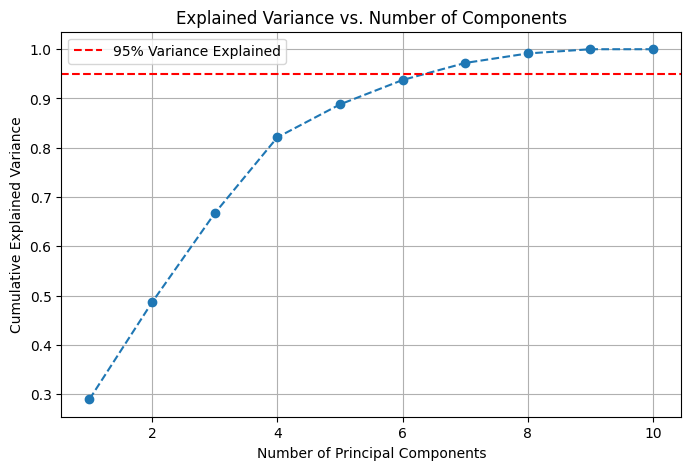

In [4]:
pca = PCA()
pca.fit(scaled_features)

# Cumulative explained variance
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Explained Variance vs. Number of Components')
plt.axhline(y=0.95, color='r', linestyle='--', label='95% Variance Explained')
plt.legend(loc='best')
plt.grid()
plt.show()

In [5]:
pca = PCA(n_components = 7)
reduced_features = pca.fit_transform(scaled_features)

num_components = reduced_features.shape[1]
column_names = [f'PC{i+1}' for i in range(num_components)]

reduced_features = pd.DataFrame(reduced_features, columns=column_names)
print(f"length of df {len(reduced_features)}")

subsampled_df = reduced_features.sample(n=30_000, random_state=41)
print("reduce to 30000")


length of df 63821
reduce to 30000


In [6]:
agglo_model = AgglomerativeClustering(linkage='ward')
clusters = agglo_model.fit_predict(subsampled_df)
den_data = linkage(subsampled_df, method='ward')

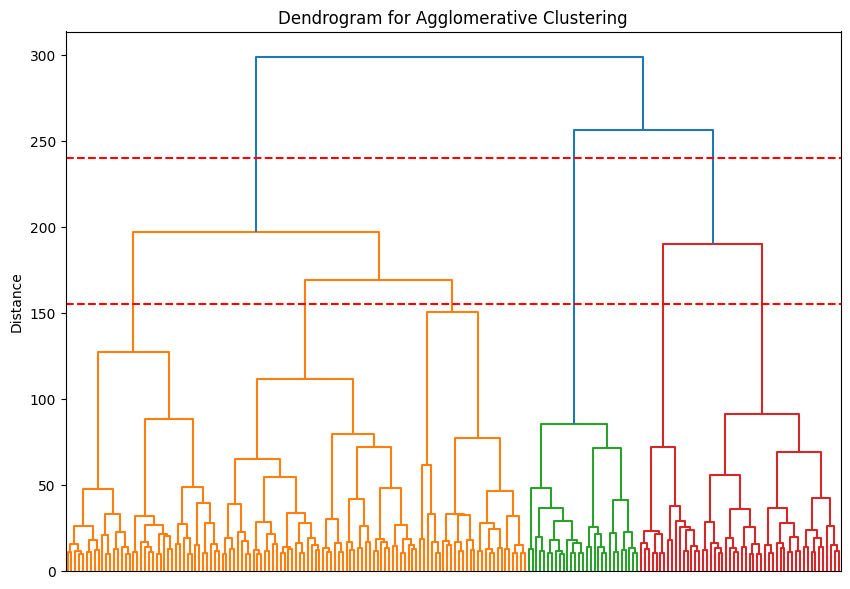

In [7]:
# Plot the dendrogram
plt.figure(figsize=(10, 7))
dendrogram(
    den_data,
    truncate_mode='lastp',
    p=200,  # Show the last 200 clusters
)
plt.xticks([])
plt.axhline(y=155, color='red', linestyle='--')
plt.axhline(y=240, color='red', linestyle='--')
plt.title("Dendrogram for Agglomerative Clustering")
plt.ylabel("Distance")
plt.show()